# Rotary spectra for Concordiasi and Strateole-2 data

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import matplotlib.cm
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy import interpolate
import scipy.signal
from mpl_toolkits.basemap import Basemap
warnings.simplefilter("ignore")

# For determining which times are day or night
import datetime
import pytz
import timezonefinder
import astral, astral.sun
from tqdm.notebook import tqdm

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()
    
# Replace Basemap with Cartopy:
import cartopy.crs as ccrs
import matplotlib.ticker as mticker

### Constants

In [2]:
# Physical constants
g = 9.806 # (m/s**2); acceleration due to gravity
cp = 1005 # (J/kg/K); the specific heat at constant pressure
R = 287 # (J/kg/K); the gas constant for dry air
Omega = 7.27E-5 # (s-1); the rotation rate of the Earth

# Time series properties
dt = 0.5 # (minutes) the time step of the interpolated data
#dt = 2 # (minutes)

# Thresholds for limiting the size of spectra
GW_PERIOD_MIN = 10 # (minutes) the minimum period for frequency-integrated momentum fluxes
GW_PERIOD_MAX = 1*24*60 # (minutes) the maximum period for GW packets is the minimum of this and the Coriolis period

# Wavelet parameters
omega0 = 8 # the normalized Morlet wavelet frequency
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98

### Load in the data

In [3]:
#flights = pd.read_feather('Concordiasi_with_ERA5_5_interpolated.feather')
flights = pd.read_feather('Strateole2_with_ERA5_4_interpolated.feather')
flights

,flight_id,time,latitude,longitude,altitude,pressure,wind_u,wind_v,T_ERA5,N2_ERA5,superpressure,segment_id
0,C0_01_STR1,2019-11-12 22:25:30,-4.836130,55.593712,20297.688624,53.897755,0.392599,-8.409890,203.430391,0.000691,8.270000,0
1,C0_01_STR1,2019-11-12 22:26:00,-4.838373,55.593802,20297.000000,53.897010,0.275275,-8.363094,203.430718,0.000691,8.209750,0
2,C0_01_STR1,2019-11-12 22:26:30,-4.840622,55.593861,20303.627514,53.822979,0.208103,-8.508461,203.463195,0.000691,8.200000,0
3,C0_01_STR1,2019-11-12 22:27:00,-4.842951,55.593915,20305.935137,53.775627,0.192059,-8.919195,203.483963,0.000691,8.690159,0
4,C0_01_STR1,2019-11-12 22:27:30,-4.845411,55.593966,20299.019538,53.819265,0.137937,-8.885177,203.464825,0.000691,8.770000,0
...,...,...,...,...,...,...,...,...,...,...,...,...
3685569,C1_17_TTL3,2021-12-16 12:31:00,-2.212779,125.869692,18639.777133,71.023424,-3.031736,3.200112,192.007890,0.000810,10.779291,74
3685570,C1_17_TTL3,2021-12-16 12:31:30,-2.211940,125.868848,18621.344802,71.260980,-3.256378,2.967137,191.965922,0.000809,10.484118,74
3685571,C1_17_TTL3,2021-12-16 12:32:00,-2.211183,125.867939,18599.995817,71.532102,-3.427718,2.669256,191.918319,0.000809,10.158603,74
3685572,C1_17_TTL3,2021-12-16 12:32:30,-2.210504,125.867000,18591.404062,71.649013,-3.458552,2.449228,191.897890,0.000808,9.918572,74


### Wavelet analysis function

In [4]:
## WAVELET ANALYSIS
# All equation and table numbers are from Torrence and Compo (1998)

# Create a dataclass for the variables returned from the analysis
@dataclass
class ReturnValue:
    N_pad: float;
    #X_recon: float;
    wave: float;
    #wave_power: float;
    #total_power: float;
    #global_power: float;
    global_power_rescaling: float;
    #total_global_power: float;
    C_delta: float;
    s: float;
    frequency: float;
    period: float;
    coi: float;
    #fftfreq: float;
    #fft: float;
    #fft_power: float;
    #fft_total_power: float;
    #fft_power_rescaling: float;
                    
# The input time series must have a mean of zero
def run_Morlet_CWT(X,dt,omega0,dj):
        
    N = np.size(X)
    std = np.std(X)
    var = std**2

    # Add zero padding and normalize to unit variance
    # The length of the new time series is 2*N for N even, 2*N + 1 for N odd
    N_pad = int(np.ceil(N/2))
    X_norm = np.zeros(N + 2*N_pad)
    X_norm[N_pad:N+N_pad] = X
    X_norm = X_norm/np.std(X_norm)
    N = N + 2*N_pad
    
    # Take the FFT of X_norm and make the frequencies (Eq. 5)
    X_norm_fft = np.fft.fft(X_norm)

    # Calculate the scales and Fourier equivalent frequencies and periods
    s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
    J = (1/dj)*np.log2(N*dt/s0) # (Eq. 10)
    J = int(np.ceil(J))
    s = s0*2**(dj*np.arange(J+1)) # (Eq. 9)
    s_tiled = np.tile(s,(N,1)).swapaxes(0,1)
    period = 4*np.pi*s/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    frequency = 1/period
    nscales = s.size
    
    # Loop through the scales to calculate the wavelet transform
    omega = 2*np.pi*np.fft.fftfreq(N)/dt # (Eq. 5) np.fft.fftfreq outputs (0,1,2,...)/N
    wave = np.nan*(1+1j)*np.ones(shape=(nscales,N))
    wave_delta = np.nan*np.ones(nscales)
    for i in np.arange(nscales):
        
        # Calculate the wavelet function (np.heaviside(0,0) = 0, so psi_hat(0) = 0 and the 
        # wavelet is admissible by construction (Section 3.3 of Farge 1992))
        psi_hat_0 = (np.pi**-0.25)*np.heaviside(omega,0)*np.exp(-0.5*(s[i]*omega - omega0)**2) # (Table 1)
        psi_hat = np.sqrt(2*np.pi*s[i]/dt)*psi_hat_0 # (Eq. 6) 
        
        # Calculate the wavelet transform
        wave[i,:] = np.fft.ifft(X_norm_fft*np.conj(psi_hat)) # (Eq. 4)
    
    # Estimate the reconstruction factor C_delta
    # Force the wavelet power spectrogram to have unit variance:
    C_delta = (dj*dt/N)*np.sum(np.abs(wave**2)/s_tiled) # (Eq. 14)
    
    ## Reconstruct the input time series
    #psi_0_0 = np.pi**-0.25 # (Table 2)
    #X_norm_recon = (dj*np.sqrt(dt)/(C_delta*psi_0_0))*np.sum(np.real(wave)/np.sqrt(s_tiled),axis=0) # (Eq. 11)
    
    # Calculate dimensional quantities
    N = N - 2*N_pad # N now matches the input time series length again
    ## The scaling is chosen so that the values are correct after the zero padding is removed
    #var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    #wave_power = (var/var_ratio)*np.abs(wave)**2
    #global_power = (1/N)*np.sum(wave_power, axis=1) # (Eq. 2)
    #total_power = (dj*dt/C_delta)*np.sum(wave_power/s_tiled, axis=0) # (Eq. 24)
    #total_global_power = (dj*dt/C_delta)*np.sum(global_power/s) # (Eq. 14)
    #global_total_power = (1/N)*np.sum(total_power)
    #X_recon = np.sqrt(var/var_ratio)*X_norm_recon # This (almost) equals the input time series + zero padding
    
    # Define a scaling so that the integral of the global power times the frequency
    # over the natural logarithm of the frequency equals the total variance. This helps
    # when plotting and comparing the global power spectrum to the FFT power spectrum.
    # Combining Eq. 9, Eq. 14, and Table 1:
    global_power_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    
    # Calculate the COI (outputs the period versus time)
    coi = dt*np.arange(N)*(2**-0.5) # TC98 table 1
    coi = 4*np.pi*coi/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    coi = np.minimum(coi, np.flipud(coi))
    
    ## FFT analysis
    #ind_switchfreq_fft = 1 + int(np.floor(N/2))
    #fft = np.fft.fft(X/std)
    #fftfreq = np.fft.fftfreq(N,dt)
    #fft = fft[:ind_switchfreq_fft] # turn into a one-sided spectrum
    #fftfreq = np.abs(fftfreq[:ind_switchfreq_fft]) # turn into a one-sided spectrum
    #fft_power = (2*var/N)*np.abs(fft)**2 # dimensional power spectra 
    #fft_power[0] = fft_power[0]/2 # don't double-count the zero-frequency power
    #fft_total_power = (1/N)*np.sum(fft_power)
    #fft_power_rescaling = dt # a rescaling of fft_power so the integral over frequency = variance
        
    return ReturnValue(N_pad,
                       #X_recon,
                       wave,
                       #wave_power,
                       #total_power,
                       #global_power,
                       global_power_rescaling,
                       #total_global_power,
                       C_delta,
                       s,
                       frequency,
                       period,
                       coi)
                       #fftfreq,
                       #fft,
                       #fft_power,
                       #fft_total_power,
                       #fft_power_rescaling)

### Analyze the segment

In [5]:
def analyze_segment(segment,dt,omega0,dj,R,g,cp,Omega,GW_PERIOD_MAX,GW_PERIOD_MIN):

    # Convert time to a numpy array with units of minutes
    t = np.array((segment.time - segment.time.iloc[0])/pd.Timedelta('1 minutes'))
    N = np.size(t)
    # Make other variables arrays
    u = np.array(segment.wind_u)
    v = np.array(segment.wind_v)
    pt = 100*np.array(segment.pressure) # the Concordiasi data has pressure units of hPa; convert to Pa
    altitude = np.array(segment.altitude)
    balloon_lat = np.array(segment.latitude)
    T_env = np.array(segment.T_ERA5)
    Nref = np.sqrt(np.array(segment.N2_ERA5))
    
    # Calculate segment mean environmental properties
    rho_bar = np.nanmean(pt/(R*T_env))
    T_env = np.nanmean(T_env)
    Nref = np.nanmean(Nref)
    
    # Calculate the environmental lapse rate
    dTdz_env = (T_env/g)*(Nref**2) - (g/cp) # VH14 Eq. 6
    
    # Calculate the segment mean density scale height
    H = T_env/(dTdz_env + g/R)
    
    # Calculate the segment mean Coriolis parameter
    f = np.mean(2*Omega*np.sin(np.pi*balloon_lat/180)) 
    
    # Calculate Z_EDS
    Z_EDS = ((g/cp) + dTdz_env)/((g/R) + dTdz_env) # Vincent and Alexander 2020, Eq. 7
    
    # Create time series of anomalies by detrending
    u = scipy.signal.detrend(u)
    v = scipy.signal.detrend(v)
    pt = scipy.signal.detrend(pt)
    delta_b = scipy.signal.detrend(altitude)
    
    # Calculate delta_theta and w, using Z_EDS
    delta_theta = delta_b/Z_EDS
    w = np.zeros(shape=(N)) # choose not to worry about the first and last value of w
    w[1:-1] = 0.5*(delta_theta[2:] - delta_theta[:-2])/(60*dt)
    
    # Run the wavelet analyses on the segment
    segment_mean_spectra_output = segment_spectra(t,w,u,v,delta_theta,pt,balloon_lat,
                                                  omega0,dt,dj,
                                                  Nref,rho_bar,Omega,Z_EDS,H,
                                                  GW_PERIOD_MAX,GW_PERIOD_MIN)
    
    return segment_mean_spectra_output

### Calculate spectra

In [6]:
@dataclass
class ReturnValue2:
    period: float;
    R_spectra_sum: float;
    R_theory_sum: float;
    CWplusCCW_sum: float;
    Ekh_spectra_sum: float;
    Ekv_spectra_sum: float;
    Ep_spectra_sum: float;
    Etotal_spectra_sum: float;
    EpEkhRatio_theory_sum: float;
    Etot_kh_theory_sum: float;
    Etot_p_theory_sum: float;
    n_spectra_sum: float;

def segment_spectra(t,w,u,v,delta_theta,pt,balloon_lat,
                    omega0,dt,dj,
                    Nref,rho_bar,Omega,Z_EDS,H,
                    GW_PERIOD_MAX,GW_PERIOD_MIN):

    N = np.size(t)

    # Time series' variance
    std_w = np.std(w)
    std_u = np.std(u)
    std_v = np.std(v)
    std_delta_theta = np.std(delta_theta)
    std_pt = np.std(pt)
    var_w = std_w**2
    var_u = std_u**2
    var_v = std_v**2
    var_delta_theta = std_delta_theta**2
    var_pt = std_pt**2
    
    # Run the wavelet analysis
    w_output = run_Morlet_CWT(w,dt,omega0,dj)
    u_output = run_Morlet_CWT(u,dt,omega0,dj)
    v_output = run_Morlet_CWT(v,dt,omega0,dj)
    delta_theta_output = run_Morlet_CWT(delta_theta,dt,omega0,dj)
    # Pull out a couple common variables to make some calculations easier
    period = u_output.period; frequency = u_output.frequency; scale = u_output.s
    N_pad = u_output.N_pad; coi = u_output.coi
    nscales = np.size(scale)
    var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    
    
    
    # Rotary spectral analysis following Guest et al. '00, Conway et al. '19, Podglajen et al. '20
    #U = np.sqrt(var_u/var_ratio)*np.conj(u_output.wave) + 1j*np.sqrt(var_v/var_ratio)*np.conj(v_output.wave)
    #U_minus = np.sqrt(var_u/var_ratio)*u_output.wave + 1j*np.sqrt(var_v/var_ratio)*v_output.wave
    U = np.sqrt(u_output.global_power_rescaling*var_u/var_ratio)*np.conj(u_output.wave) + \
        1j*np.sqrt(v_output.global_power_rescaling*var_v/var_ratio)*np.conj(v_output.wave)
    U_minus = np.sqrt(u_output.global_power_rescaling*var_u/var_ratio)*u_output.wave + \
              1j*np.sqrt(v_output.global_power_rescaling*var_v/var_ratio)*v_output.wave
    CCW = 0.5*np.abs(U_minus)**2
    CW = 0.5*np.abs(U)**2
    f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat/180),(nscales,1))
    frequency_rad = np.tile(2*np.pi*frequency/60,(N,1)).swapaxes(0,1)
    #R_theory = (f_temp + frequency_rad)**2/(2*(f_temp**2 + frequency_rad**2))
    R_theory = 0.5 + f_temp*frequency_rad/(f_temp**2 + frequency_rad**2)
    
    # The ratio of Ep to Ekh (Podglajen et al., 2016)
    f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat/180),(nscales,1))
    frequency_rad = np.tile(2*np.pi*frequency/60,(N,1)).swapaxes(0,1)
    EpEkhRatio_theory = (Nref**2)/(Nref**2 - frequency_rad**2)
    EpEkhRatio_theory = EpEkhRatio_theory*(frequency_rad**2 - f_temp**2)/(frequency_rad**2 + f_temp**2)
    #del f_temp, frequency_rad
    
    # Etotal from Ekh (same method as Podglajen et al., 2016)
    #f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat/180),(nscales,1))
    #frequency_rad = np.tile(2*np.pi*frequency/60,(N,1)).swapaxes(0,1)
    #EkhEtotRatio_theory = 0.5*(Nref**2 - frequency_rad**2)*(frequency_rad**2 + f_temp**2)/(frequency_rad**2)
    #EkhEtotRatio_theory = EkhEtotRatio_theory/(Nref**2 - f_temp**2)
    Etot_kh_theory = 2*(frequency_rad**2)*(Nref**2 - f_temp**2)/(Nref**2 - frequency_rad**2)
    Etot_kh_theory = Etot_kh_theory/(frequency_rad**2 + f_temp**2)
    #del f_temp, frequency_rad
    
    # Etotal from Ep (same method as Podglajen et al., 2016)
    #f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat/180),(nscales,1))
    #frequency_rad = np.tile(2*np.pi*frequency/60,(N,1)).swapaxes(0,1)
    #EpEtotRatio_theory = 0.5*(Nref**2)*(frequency_rad**2 - f_temp**2)/(frequency_rad**2)
    #EpEtotRatio_theory = EpEtotRatio_theory/(Nref**2 - f_temp**2)
    Etot_p_theory = 2*(frequency_rad**2)*(Nref**2 - f_temp**2)/(Nref**2)
    Etot_p_theory = Etot_p_theory/(frequency_rad**2 - f_temp**2)
    del f_temp, frequency_rad
    
    
    # Potential and kinetic energies
    wave_Ekh = (0.5/var_ratio)*(var_u*u_output.global_power_rescaling*np.abs(u_output.wave)**2 + 
                                var_v*v_output.global_power_rescaling*np.abs(v_output.wave)**2)
    wave_Ekv = (0.5/var_ratio)*(var_w*w_output.global_power_rescaling*np.abs(w_output.wave)**2)
    wave_Ep = 0.5*(Nref**2)*(var_delta_theta/var_ratio)*delta_theta_output.global_power_rescaling* \
              np.abs(delta_theta_output.wave)**2
    wave_Etotal = wave_Ekh + wave_Ekv + wave_Ep
    
    
    
    ## PROCESS THE WAVELET
    # Remove zero padding and calculate the rescaled horizontal kinetic and potential energies
    CW = CW[:,N_pad:N+N_pad]
    CCW = CCW[:,N_pad:N+N_pad]
    wave_Ekh = wave_Ekh[:,N_pad:N+N_pad]
    wave_Ekv = wave_Ekv[:,N_pad:N+N_pad]
    wave_Ep = wave_Ep[:,N_pad:N+N_pad]
    wave_Etotal = wave_Etotal[:,N_pad:N+N_pad]
    Etot_kh_theory = Etot_kh_theory*wave_Ekh
    Etot_p_theory = Etot_p_theory*wave_Ep
    # Identify wavelet coefficients inside the COI
    temp1 = np.tile(period,(N,1)).swapaxes(0,1)
    temp2 = np.tile(coi,(nscales,1))
    temp1[temp1 > temp2] = np.nan
    del temp2
    temp1 = temp1/temp1
    # Identify wavelet coefficients with frequencies lower than f or the minimum GW frequency
    temp2 = 2*60*Omega*np.sin(np.pi*np.abs(balloon_lat)/180) # Coriolis frequency in rad/min
    temp2 = 2*np.pi/temp2
    temp2 = np.minimum(temp2,GW_PERIOD_MAX)
    temp2 = np.tile(temp2,(nscales,1))
    temp3 = np.tile(period,(N,1)).swapaxes(0,1)
    temp2[temp2 < temp3] = np.nan
    del temp3
    temp2 = temp2/temp2
    temp1 = temp1*temp2
    del temp2
    # Delete the offending wavelet coefficients
    CW = CW*temp1
    CCW = CCW*temp1
    R_theory = R_theory*temp1
    wave_Ekh = wave_Ekh*temp1
    wave_Ekv = wave_Ekv*temp1
    wave_Ep = wave_Ep*temp1
    wave_Etotal = wave_Etotal*temp1
    EpEkhRatio_theory = EpEkhRatio_theory*temp1
    Etot_kh_theory = Etot_kh_theory*temp1
    Etot_p_theory = Etot_p_theory*temp1
    n_spectra = temp1.copy()
    del temp1
    # Identify the periods less than or equal to GW_PERIOD_MAX
    nscales_new = np.arange(nscales)
    nscales_new = nscales_new[period <= GW_PERIOD_MAX]
    nscales_new = nscales_new.size
    period = period[:nscales_new]
    CW = CW[:nscales_new,:]
    CCW = CCW[:nscales_new,:]
    R_theory = R_theory[:nscales_new,:]
    wave_Ekh = wave_Ekh[:nscales_new,:]
    wave_Ekv = wave_Ekv[:nscales_new,:]
    wave_Ep = wave_Ep[:nscales_new,:]
    wave_Etotal = wave_Etotal[:nscales_new,:]
    EpEkhRatio_theory = EpEkhRatio_theory[:nscales_new,:]
    Etot_kh_theory = Etot_kh_theory[:nscales_new,:]
    Etot_p_theory = Etot_p_theory[:nscales_new,:]
    n_spectra = n_spectra[:nscales_new,:]
    # Identify the periods greater or equal to GW_PERIOD_MIN
    ind = np.arange(nscales_new)
    ind = ind[period >= GW_PERIOD_MIN]
    ind = ind[0]
    period = period[ind:]
    CW = CW[ind:,:]
    CCW = CCW[ind:,:]
    R_theory = R_theory[ind:,:]
    wave_Ekh = wave_Ekh[ind:,:]
    wave_Ekv = wave_Ekv[ind:,:]
    wave_Ep = wave_Ep[ind:,:]
    wave_Etotal = wave_Etotal[ind:,:]
    EpEkhRatio_theory = EpEkhRatio_theory[ind:,:]
    Etot_kh_theory = Etot_kh_theory[ind:,:]
    Etot_p_theory = Etot_p_theory[ind:,:]
    n_spectra = n_spectra[ind:,:]
    nscales_new = period.size
    
    # Sum over time
    R_spectra_sum = np.nansum(CW,axis=1)
    R_theory_sum = np.nansum((CW+CCW)*R_theory,axis=1)
    CWplusCCW_sum = np.nansum(CW+CCW,axis=1)
    Ekh_spectra_sum = np.nansum(wave_Ekh,axis=1)
    Ekv_spectra_sum = np.nansum(wave_Ekv,axis=1)
    Ep_spectra_sum = np.nansum(wave_Ep,axis=1)
    Etotal_spectra_sum = np.nansum(wave_Etotal,axis=1)
    EpEkhRatio_theory_sum = np.nansum(wave_Ekh*EpEkhRatio_theory,axis=1)
    Etot_kh_theory_sum = np.nansum(Etot_kh_theory,axis=1)
    Etot_p_theory_sum = np.nansum(Etot_p_theory,axis=1)
    n_spectra_sum = np.nansum(n_spectra,axis=1)
    
    
    
    return ReturnValue2(period,
                        R_spectra_sum,
                        R_theory_sum,
                        CWplusCCW_sum,
                        Ekh_spectra_sum,
                        Ekv_spectra_sum,
                        Ep_spectra_sum,
                        Etotal_spectra_sum,
                        EpEkhRatio_theory_sum,
                        Etot_kh_theory_sum,
                        Etot_p_theory_sum,
                        n_spectra_sum)

In [7]:
# Do the analysis

# Define the analyzed fields
temp = run_Morlet_CWT(np.ones(int(2*24*60/dt)),dt,omega0,dj)
temp = temp.period
temp = temp[temp >= GW_PERIOD_MIN]
temp = temp[temp <= GW_PERIOD_MAX]
nscales_new = temp.size
R_spectra_sum = np.zeros(nscales_new)
R_theory_sum = np.zeros(nscales_new)
CWplusCCW_sum = np.zeros(nscales_new)
Ekh_spectra_sum = np.zeros(nscales_new)
Ekv_spectra_sum = np.zeros(nscales_new)
Ep_spectra_sum = np.zeros(nscales_new)
Etotal_spectra_sum = np.zeros(nscales_new)
EpEkhRatio_theory_sum = np.zeros(nscales_new)
Etot_kh_theory_sum = np.zeros(nscales_new)
Etot_p_theory_sum = np.zeros(nscales_new)
n_spectra_sum = np.zeros(nscales_new)

# Analyze each segment
segment_ids = flights.segment_id.unique()
n_segments = flights.segment_id.nunique()
for i in np.arange(n_segments):
    segment = flights[flights.segment_id == segment_ids[i]]
    print('Analyzing segment', i+1, 'out of', n_segments, 'segments')
    print('Segment length:', segment.time.max() - segment.time.min())
    print('Current time:', datetime.datetime.now())
    temp = analyze_segment(segment,dt,omega0,dj,R,g,cp,Omega,GW_PERIOD_MAX,GW_PERIOD_MIN)
    R_spectra_sum = R_spectra_sum + temp.R_spectra_sum
    R_theory_sum = R_theory_sum + temp.R_theory_sum
    CWplusCCW_sum = CWplusCCW_sum + temp.CWplusCCW_sum
    Ekh_spectra_sum = Ekh_spectra_sum + temp.Ekh_spectra_sum
    Ekv_spectra_sum = Ekv_spectra_sum + temp.Ekv_spectra_sum
    Ep_spectra_sum = Ep_spectra_sum + temp.Ep_spectra_sum
    Etotal_spectra_sum = Etotal_spectra_sum + temp.Etotal_spectra_sum
    EpEkhRatio_theory_sum = EpEkhRatio_theory_sum + temp.EpEkhRatio_theory_sum
    Etot_kh_theory_sum = Etot_kh_theory_sum + temp.Etot_kh_theory_sum
    Etot_p_theory_sum = Etot_p_theory_sum + temp.Etot_p_theory_sum
    n_spectra_sum = n_spectra_sum + temp.n_spectra_sum
    print('')
period = temp.period

# Organize the output and save
R_spectra = R_spectra_sum/CWplusCCW_sum
R_theory = R_theory_sum/CWplusCCW_sum
Ekh_spectra = Ekh_spectra_sum/n_spectra_sum
Ekv_spectra = Ekv_spectra_sum/n_spectra_sum
Ep_spectra = Ep_spectra_sum/n_spectra_sum
Etotal_spectra = Etotal_spectra_sum/n_spectra_sum
EpEkhRatio_theory = EpEkhRatio_theory_sum/Ekh_spectra_sum
EkhEtotRatio_theory = Ekh_spectra_sum/Etot_kh_theory_sum
EpEtotRatio_theory = Ep_spectra_sum/Etot_p_theory_sum
data = [period,
        R_spectra,
        R_theory,
        Ekh_spectra,
        Ekv_spectra,
        Ep_spectra,
        Etotal_spectra,
        EpEkhRatio_theory,
        EkhEtotRatio_theory,
        EpEtotRatio_theory]
#np.savez('Concordiasi_R_energies_spectra_omega0_8.npz', *data) 
np.savez('Strateole2_R_energies_spectra_omega0_8.npz', *data) 

Analyzing segment 1 out of 57 segments
Segment length: 23 days 10:04:00
Current time: 2025-12-17 15:57:01.890810

Analyzing segment 2 out of 57 segments
Segment length: 8 days 20:14:00
Current time: 2025-12-17 15:57:36.640068

Analyzing segment 3 out of 57 segments
Segment length: 7 days 20:14:00
Current time: 2025-12-17 15:57:44.526403

Analyzing segment 4 out of 57 segments
Segment length: 14 days 14:29:00
Current time: 2025-12-17 15:57:51.327038

Analyzing segment 5 out of 57 segments
Segment length: 2 days 02:29:00
Current time: 2025-12-17 15:58:04.641366

Analyzing segment 6 out of 57 segments
Segment length: 43 days 04:16:30
Current time: 2025-12-17 15:58:06.094152

Analyzing segment 7 out of 57 segments
Segment length: 27 days 09:32:30
Current time: 2025-12-17 15:59:47.009992

Analyzing segment 8 out of 57 segments
Segment length: 75 days 10:02:00
Current time: 2025-12-17 16:00:23.541474

Analyzing segment 9 out of 57 segments
Segment length: 3 days 19:52:00
Current time: 2025-1

### Load in the analyzed data

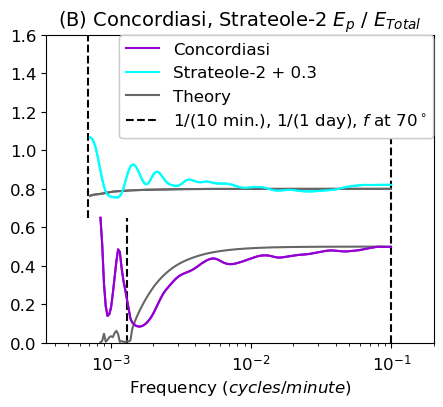

In [4]:
# Fig. S3B

container = np.load('Concordiasi_R_energies_spectra_omega0_8.npz')
data = [container[key] for key in container]
period_C = data[0]
Ep_spectra_C = data[5]
Etotal_spectra_C = data[6]
EpEtotRatio_theory_C = data[9]

container = np.load('Strateole2_R_energies_spectra_omega0_8.npz')
data = [container[key] for key in container]
period_S2 = data[0]
Ep_spectra_S2 = data[5]
Etotal_spectra_S2 = data[6]
EpEtotRatio_theory_S2 = data[9]

frequency_C = 1/period_C
frequency_S2 = 1/period_S2

temp_f = 2*Omega*np.sin(np.pi*70/180)
temp_f = 60*temp_f/(2*np.pi)

offset = 0.3
ymax = 1.6
ymin = 0.0
ysplit = 0.65

fig, ax = plt.subplots(figsize=(5,4))
temp1 = Ep_spectra_S2/Etotal_spectra_S2
temp2 = Ep_spectra_C/Etotal_spectra_C
line1, = ax.plot(frequency_C,temp2 + 0*offset,c=matplotlib.colors.CSS4_COLORS['darkviolet'],
                 label = 'Concordiasi')
line2, = ax.plot(frequency_S2,temp1 + 1*offset,c=matplotlib.colors.CSS4_COLORS['cyan'],
                 label = 'Strateole-2 + 0.3')
line3, = ax.plot(frequency_S2,EpEtotRatio_theory_S2 + 1*offset,color=[0.4,0.4,0.4],
                 label = 'Theory')
line4, = ax.plot([1/10, 1/10], [ymin, ymax],'--k',
                 label = '1/(10 min.), 1/(1 day), $f$ at 70$^\circ$')
ax.plot([1/1440, 1/1440], [ysplit, ymax],'--k')
ax.plot([temp_f, temp_f], [ymin, ysplit],'--k')
ax.plot(frequency_S2,EpEtotRatio_theory_S2 + 1*offset,color=[0.4,0.4,0.4])
ax.plot(frequency_C,EpEtotRatio_theory_C + 0*offset,color=[0.4,0.4,0.4])
ax.plot(frequency_S2,temp1 + 1*offset,c=matplotlib.colors.CSS4_COLORS['cyan'])
ax.plot(frequency_C,temp2 + 0*offset,c=matplotlib.colors.CSS4_COLORS['darkviolet'])
ax.set_xscale('log')
ax.set_xlim(1/(2*24*60),1/5)
ax.set_ylim(ymin,ymax)
ax.set_yticks([0.0,0.2,0.4,0.6,0.8,1,1.2,1.4,1.6])
ax.tick_params(labelsize=12)
ax.set_title('(B) Concordiasi, Strateole-2 $E_{p}$ / $E_{Total}$', fontsize=14)
ax.set_xlabel('Frequency $(cycles/minute)$', fontsize=12)
first_legend = ax.legend(handles=[line1, line2, line3, line4],
                         loc='upper right', bbox_to_anchor=(1.02, 1.025), framealpha=1, fontsize=12)
ax.add_artist(first_legend);
#ax.legend(handles=[line4],
#          loc='lower right', bbox_to_anchor=(1.02, 0.5), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp31.pdf', format='pdf', bbox_inches='tight');